# Analisis ANOVA, visualisasi, dan tabel — RAK faktorial 2×2×4

Notebook ini **hanya membaca `results.csv`** (hasil notebook model) dan tidak melatih apa pun. Taruh `results.csv` di folder yang sama dengan notebook ini.

**Kebutuhan:** `pip install pandas numpy scipy statsmodels matplotlib` (sekali saja bila belum terpasang).

**Isi:** (1) tabel deskriptif, (2) ANOVA tiga arah dengan blok, (3) uji asumsi, (4) grafik, (5) uji lanjut Tukey dengan huruf kelompok,
(6) ekspor tabel dan gambar ke folder `anova_<respon>`. Untuk respon sekunder, ganti `RESP = "pred_acc"` di sel pertama dan jalankan ulang dari atas.

## 0. Muat data dan konfigurasi

In [1]:
import os
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
from scipy.stats import studentized_range
from IPython.display import display

# ===================== KONFIGURASI =====================
RESP      = "test_acc"   # respon utama. Ganti "pred_acc" (respon sekunder) lalu jalankan ulang dari atas
ASIN_SQRT = False        # True bila asumsi gagal (respon proporsi): transformasi arcsin(sqrt(y))
ALPHA     = 0.05
CSV       = "results.csv"   # file hasil dari notebook model, sejajar dengan notebook ini
# =======================================================

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25})

path = CSV
OUT = f"anova_{RESP}"          # folder keluaran (tabel CSV dan gambar PNG)
os.makedirs(OUT, exist_ok=True)
print("Membaca :", os.path.abspath(path))
print("Keluaran:", os.path.abspath(OUT))

df = pd.read_csv(path)
missing = {"block", "source", "patch", "train_n", "run_order", RESP} - set(df.columns)
if missing:
    raise KeyError(f"Kolom tidak ada di results.csv: {missing}")
df = df.dropna(subset=[RESP]).copy()

ORDER = {"source": ["ImageNet", "HF"], "patch": ["16", "32"], "train_n": ["8", "10", "14", "16"]}
FACTORS = list(ORDER)
FNAME = {"source": "A: Sumber pre-training", "patch": "B: Patch size", "train_n": "C: Jumlah data latih (sampel/kelas)"}
df["block_n"] = df["block"].astype(int)
df["block"] = df["block"].astype(str)
for f in FACTORS:
    df[f] = pd.Categorical(df[f].astype(str), categories=ORDER[f], ordered=True)
assert df[FACTORS].notna().all().all(), "Ada level di results.csv yang tidak ada di ORDER"
df["y"] = np.arcsin(np.sqrt(df[RESP])) if ASIN_SQRT else df[RESP]
df["grp"] = df["source"].astype(str) + " · patch " + df["patch"].astype(str)
df["cell"] = df["grp"] + " · n=" + df["train_n"].astype(str)

cnt = df.groupby(FACTORS, observed=True).size()
print(f"\nRespon: {RESP}{' (arcsin-sqrt)' if ASIN_SQRT else ''} | {len(df)} run | {df.block.nunique()} blok | "
      f"{len(cnt)} perlakuan | run per sel: {sorted(cnt.unique())}")
assert cnt.nunique() == 1, "Desain tidak seimbang (jumlah run per sel berbeda); cek results.csv"

Membaca : d:\S2\s2-tmi\bahan\Anstat\tugas\Anova\results.csv
Keluaran: d:\S2\s2-tmi\bahan\Anstat\tugas\Anova\anova_test_acc

Respon: test_acc | 160 run | 10 blok | 16 perlakuan | run per sel: [np.int64(10)]


## 1. Tabel deskriptif

In [2]:
print("Tabel 1. Rata-rata ± SD respon (%) per perlakuan (SD antar blok)\n")
mean_tab = df.pivot_table(index=["source", "patch"], columns="train_n", values=RESP, aggfunc="mean", observed=True)
sd_tab = df.pivot_table(index=["source", "patch"], columns="train_n", values=RESP, aggfunc="std", observed=True)
ms = (mean_tab * 100).round(1).astype(str) + " ± " + (sd_tab * 100).round(1).astype(str)
ms.columns = [f"n = {c}" for c in ms.columns]
display(ms)

print("Tabel 2. Rata-rata respon per perlakuan (peta warna)\n")
mt_show = mean_tab.copy(); mt_show.columns = [f"n = {c}" for c in mt_show.columns]
display(mt_show.style.format("{:.1%}").background_gradient(cmap="Blues", axis=None))

print("Tabel 3. Rata-rata marginal per faktor\n")
rows = []
for f in FACTORS:
    g = df.groupby(f, observed=True)[RESP].agg(["count", "mean", "std"])
    for lev, r in g.iterrows():
        rows.append({"Faktor": FNAME[f], "Level": str(lev), "n run": int(r["count"]),
                     "Rata-rata (%)": 100 * r["mean"], "SD (%)": 100 * r["std"]})
marg = pd.DataFrame(rows).set_index(["Faktor", "Level"])
display(marg.style.format({"Rata-rata (%)": "{:.1f}", "SD (%)": "{:.1f}"}))

ms.to_csv(f"{OUT}/tabel1_mean_sd.csv"); marg.to_csv(f"{OUT}/tabel3_marginal.csv")

Tabel 1. Rata-rata ± SD respon (%) per perlakuan (SD antar blok)



n = 8      n = 10      n = 14      n = 16
source   patch                                                
ImageNet 16     73.0 ± 3.9  74.0 ± 2.9  76.3 ± 2.9  77.8 ± 2.4
         32     72.0 ± 3.0  73.8 ± 2.0  76.4 ± 3.3  78.2 ± 2.7
HF       16     75.5 ± 2.7  76.4 ± 2.9  80.6 ± 2.8  81.0 ± 3.6
         32     79.2 ± 2.9  80.5 ± 3.0  84.5 ± 2.3  83.8 ± 2.3

Tabel 2. Rata-rata respon per perlakuan (peta warna)



Tabel 3. Rata-rata marginal per faktor



## 2. ANOVA

In [3]:
formula = "y ~ C(block) + C(source) * C(patch) * C(train_n)"
model = smf.ols(formula, data=df).fit()
raw = anova_lm(model, typ=2)          # desain seimbang: Type I = II = III

NAMES = {"C(block)": "Blok", "C(source)": "A: Sumber", "C(patch)": "B: Patch", "C(train_n)": "C: Jumlah data",
         "C(source):C(patch)": "A×B", "C(source):C(train_n)": "A×C", "C(patch):C(train_n)": "B×C",
         "C(source):C(patch):C(train_n)": "A×B×C", "Residual": "Galat"}
tab = raw.copy()
tab["MS"] = tab["sum_sq"] / tab["df"]
tab["partial η²"] = tab["sum_sq"] / (tab["sum_sq"] + tab.loc["Residual", "sum_sq"])
tab.loc["Residual", "partial η²"] = np.nan
tab.index = [NAMES.get(i, i) for i in tab.index]
tab = tab[["df", "sum_sq", "MS", "F", "PR(>F)", "partial η²"]].rename(columns={"sum_sq": "JK", "PR(>F)": "p"})
star = lambda p: "" if pd.isna(p) else "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else "ns"
tab["Sig."] = tab["p"].map(star)

fp = lambda p: "" if pd.isna(p) else ("<0.001" if p < .001 else f"{p:.4f}")
print(f"Tabel 4. ANOVA RAK faktorial (model: {formula}); db galat = {int(tab.loc['Galat','df'])}\n")
display(tab.style.format({"df": "{:.0f}", "JK": "{:.5f}", "MS": "{:.5f}", "F": "{:.2f}", "p": fp, "partial η²": "{:.3f}"}, na_rep="")
        .apply(lambda r: ["font-weight:bold; background-color:#e6f2e6" if (r["p"] < ALPHA) else "" for _ in r], axis=1))

sig = [i for i in tab.index if i not in ("Blok", "Galat") and tab.loc[i, "p"] < ALPHA]
ns = [i for i in tab.index if i not in ("Blok", "Galat") and tab.loc[i, "p"] >= ALPHA]
print(f"Nyata pada α = {ALPHA}: {', '.join(sig) if sig else '(tidak ada)'}")
print(f"Tidak nyata          : {', '.join(ns) if ns else '(tidak ada)'}")
bp_ = tab.loc["Blok", "p"]
print(f"Blok {'nyata' if bp_ < ALPHA else 'tidak nyata'} (p = {fp(bp_)}, partial η² = {tab.loc['Blok','partial η²']:.2f})"
      + (" -> pengelompokan berguna" if bp_ < ALPHA else ""))
tab.to_csv(f"{OUT}/tabel4_anova.csv")

Tabel 4. ANOVA RAK faktorial (model: y ~ C(block) + C(source) * C(patch) * C(train_n)); db galat = 135



,df,JK,MS,F,p,partial η²,Sig.
Blok,9,0.02504,0.00278,3.92,<0.001,0.207,***
A: Sumber,1,0.10063,0.10063,141.63,<0.001,0.512,***
B: Patch,1,0.01203,0.01203,16.94,<0.001,0.111,***
C: Jumlah data,3,0.07809,0.02603,36.64,<0.001,0.449,***
A×B,1,0.01510,0.01510,21.25,<0.001,0.136,***
A×C,3,0.00196,0.00065,0.92,0.4336,0.020,ns
B×C,3,0.00029,0.00010,0.14,0.9373,0.003,ns
A×B×C,3,0.00069,0.00023,0.32,0.8078,0.007,ns
Galat,135,0.09592,0.00071,,,,


Nyata pada α = 0.05: A: Sumber, B: Patch, C: Jumlah data, A×B
Tidak nyata          : A×C, B×C, A×B×C
Blok nyata (p = <0.001, partial η² = 0.21) -> pengelompokan berguna


## 3. Uji asumsi

Tabel 5. Uji asumsi ANOVA



,Statistik,p,Kesimpulan
Uji,,,
Normalitas residual (Shapiro-Wilk),W = 0.9902,0.3395,terpenuhi
"Homogenitas varians (Levene, median)",F = 0.4894,0.9430,terpenuhi
Independensi residual (Durbin-Watson),DW = 2.007,,terpenuhi (≈ 2)


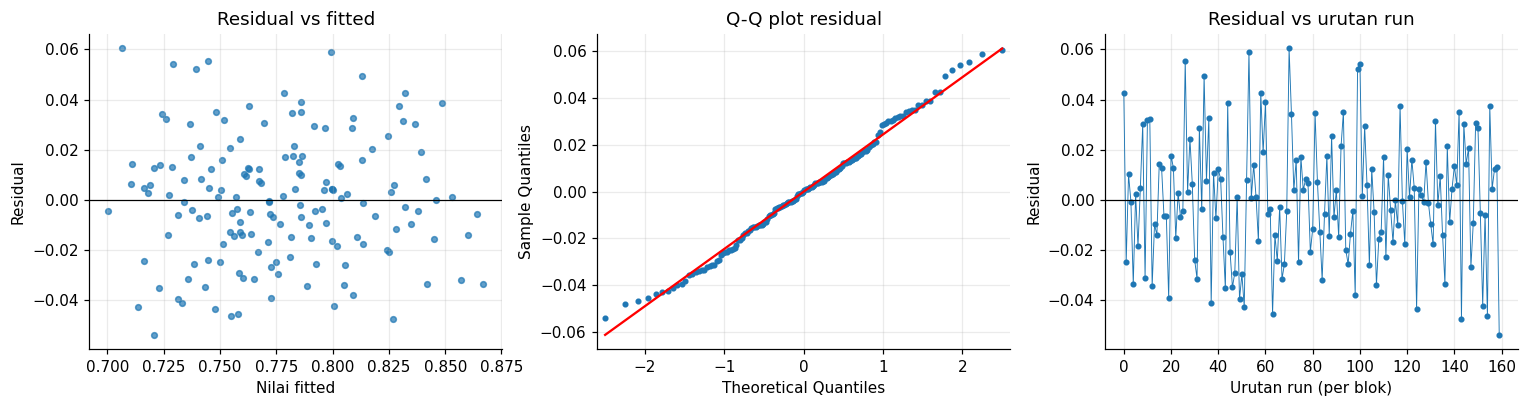

In [4]:
resid = model.resid
sw = stats.shapiro(resid)
lv = stats.levene(*[g["y"].values for _, g in df.groupby("cell", observed=True)], center="median")
seq = df.assign(resid=resid).sort_values(["block_n", "run_order"])
dw = durbin_watson(seq["resid"].values)

assume = pd.DataFrame([
    ["Normalitas residual (Shapiro-Wilk)", f"W = {sw.statistic:.4f}", sw.pvalue, "terpenuhi" if sw.pvalue > ALPHA else "TIDAK terpenuhi"],
    ["Homogenitas varians (Levene, median)", f"F = {lv.statistic:.4f}", lv.pvalue, "terpenuhi" if lv.pvalue > ALPHA else "TIDAK terpenuhi"],
    ["Independensi residual (Durbin-Watson)", f"DW = {dw:.3f}", np.nan, "terpenuhi (≈ 2)" if 1.5 < dw < 2.5 else "periksa autokorelasi"],
], columns=["Uji", "Statistik", "p", "Kesimpulan"]).set_index("Uji")
print("Tabel 5. Uji asumsi ANOVA\n")
display(assume.style.format({"p": lambda v: "" if pd.isna(v) else f"{v:.4f}"}, na_rep=""))
assume.to_csv(f"{OUT}/tabel5_asumsi.csv")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].scatter(model.fittedvalues, resid, s=14, alpha=.7); ax[0].axhline(0, c="k", lw=.8)
ax[0].set(xlabel="Nilai fitted", ylabel="Residual", title="Residual vs fitted")
sm.qqplot(resid, line="s", ax=ax[1], markersize=3); ax[1].set_title("Q-Q plot residual")
ax[2].plot(seq["resid"].values, marker="o", ms=3, lw=.6); ax[2].axhline(0, c="k", lw=.8)
ax[2].set(xlabel="Urutan run (per blok)", ylabel="Residual", title="Residual vs urutan run")
fig.tight_layout(); fig.savefig(f"{OUT}/gambar0_residual.png", dpi=170); plt.show()

## 4. Visualisasi

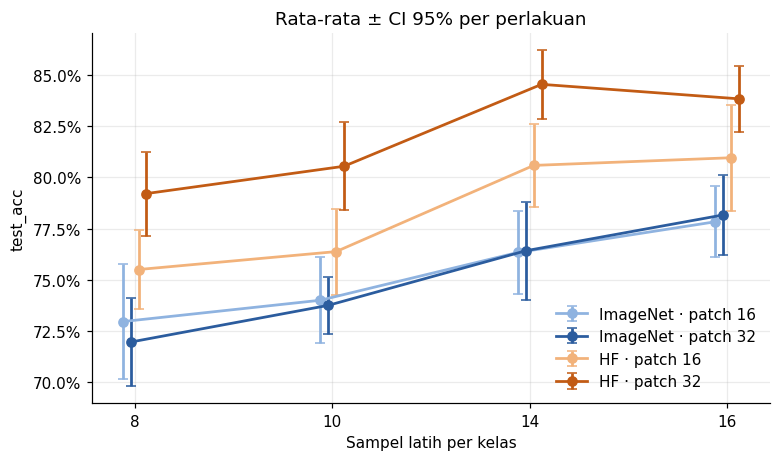

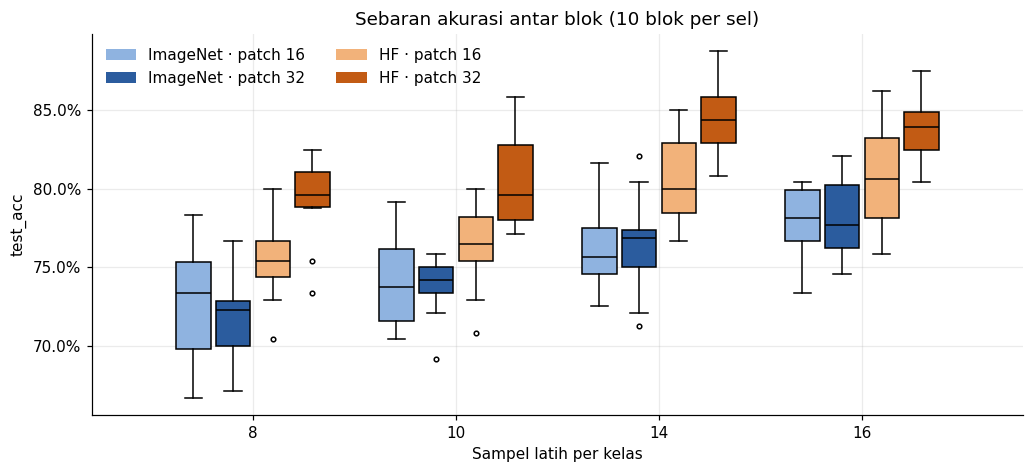

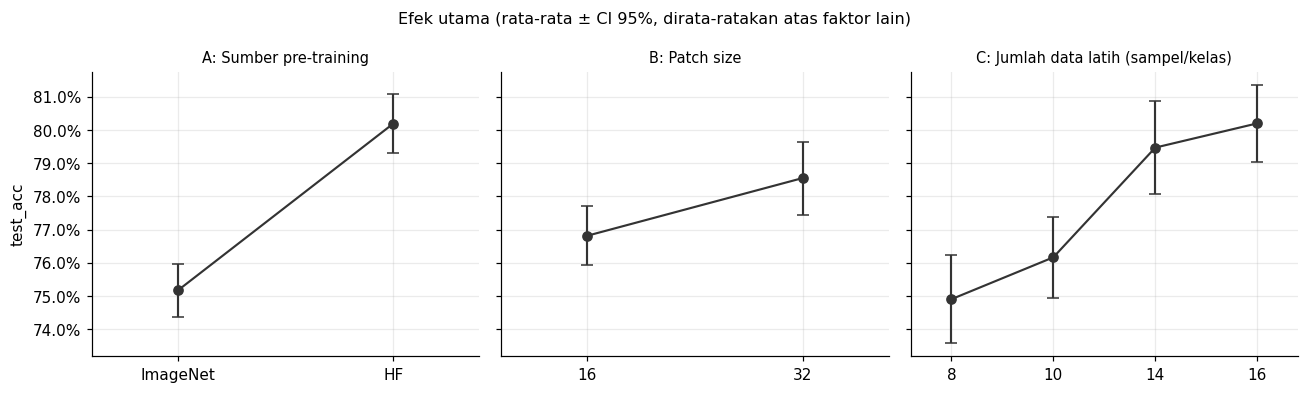

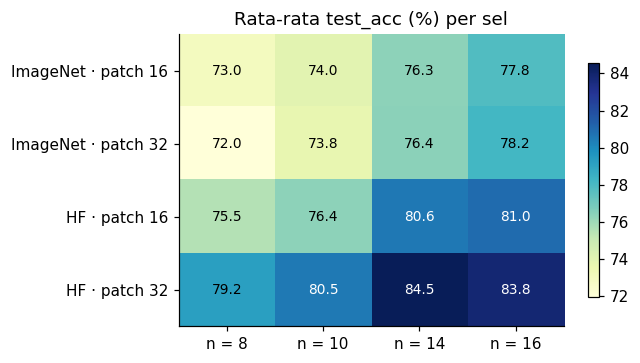

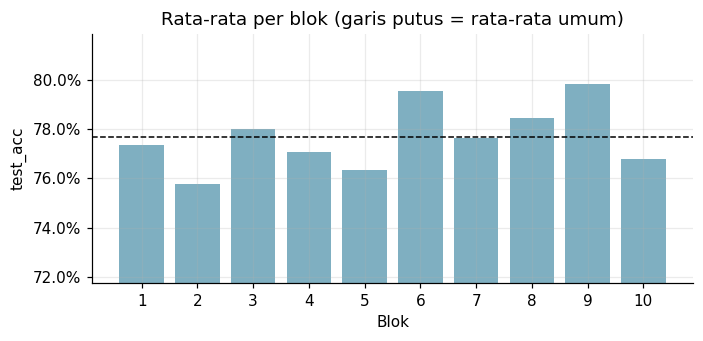

In [5]:
COL = {"ImageNet · patch 16": "#8FB3E0", "ImageNet · patch 32": "#2B5C9E",
       "HF · patch 16": "#F2B27A", "HF · patch 32": "#C25B14"}
XS = ORDER["train_n"]
pct = mt.PercentFormatter(1.0, decimals=1)
ci95 = lambda g: stats.t.ppf(.975, g["count"] - 1) * g["std"] / np.sqrt(g["count"])
def save(fig, name):
    fig.tight_layout(); fig.savefig(f"{OUT}/{name}.png", dpi=170); plt.show()

# Gambar 1. Rata-rata ± CI95 per kelompok vs jumlah data latih
fig, ax = plt.subplots(figsize=(7.2, 4.3))
for k, (gname, c) in enumerate(COL.items()):
    g = df[df.grp == gname].groupby("train_n", observed=True)[RESP].agg(["mean", "std", "count"]).reindex(XS)
    ax.errorbar(np.arange(len(XS)) + (k - 1.5) * .04, g["mean"], yerr=ci95(g), marker="o", capsize=3, color=c,
                lw=1.8, label=gname)
ax.set_xticks(range(len(XS)), XS); ax.yaxis.set_major_formatter(pct)
ax.set(xlabel="Sampel latih per kelas", ylabel=RESP, title="Rata-rata ± CI 95% per perlakuan"); ax.legend(frameon=False)
save(fig, "gambar1_interaksi")

# Gambar 2. Sebaran antar blok (boxplot)
fig, ax = plt.subplots(figsize=(9.5, 4.4)); w = .17
for gi, (gname, c) in enumerate(COL.items()):
    for xi, x in enumerate(XS):
        v = df[(df.grp == gname) & (df.train_n == x)][RESP].values
        bp = ax.boxplot(v, positions=[xi + (gi - 1.5) * w * 1.15], widths=w, patch_artist=True,
                        medianprops=dict(color="k"), flierprops=dict(markersize=3))
        bp["boxes"][0].set_facecolor(c)
ax.set_xticks(range(len(XS)), XS); ax.yaxis.set_major_formatter(pct)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, fc=c) for c in COL.values()], labels=list(COL), frameon=False, ncol=2)
ax.set(xlabel="Sampel latih per kelas", ylabel=RESP, title="Sebaran akurasi antar blok (10 blok per sel)")
save(fig, "gambar2_boxplot")

# Gambar 3. Efek utama
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for a, f in zip(ax, FACTORS):
    g = df.groupby(f, observed=True)[RESP].agg(["mean", "std", "count"])
    a.errorbar(range(len(g)), g["mean"], yerr=ci95(g), marker="o", capsize=4, color="#333", lw=1.4)
    a.set_xticks(range(len(g)), [str(i) for i in g.index]); a.set_xlim(-.4, len(g) - .6)
    a.set_title(FNAME[f], fontsize=9.5); a.yaxis.set_major_formatter(pct)
ax[0].set_ylabel(RESP); fig.suptitle("Efek utama (rata-rata ± CI 95%, dirata-ratakan atas faktor lain)", fontsize=10.5)
save(fig, "gambar3_efek_utama")

# Gambar 4. Peta panas rata-rata per sel
M = df.pivot_table(index="grp", columns="train_n", values=RESP, aggfunc="mean", observed=True).reindex(list(COL)) * 100
fig, ax = plt.subplots(figsize=(6.2, 3.4))
im = ax.imshow(M.values, cmap="YlGnBu", aspect="auto"); ax.grid(False)
ax.set_xticks(range(M.shape[1]), [f"n = {c}" for c in M.columns]); ax.set_yticks(range(M.shape[0]), M.index)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j, i, f"{M.values[i, j]:.1f}", ha="center", va="center",
                color="white" if M.values[i, j] > np.nanmean(M.values) + 2 else "black", fontsize=9)
ax.set_title(f"Rata-rata {RESP} (%) per sel"); fig.colorbar(im, ax=ax, shrink=.8)
save(fig, "gambar4_heatmap")

# Gambar 5. Rata-rata per blok
bm = df.groupby("block_n")[RESP].mean()
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.bar(bm.index.astype(str), bm.values, color="#7FAFC1"); ax.axhline(bm.mean(), c="k", lw=1, ls="--")
ax.set_ylim(max(0, bm.min() - .04), bm.max() + .02); ax.yaxis.set_major_formatter(pct)
ax.set(xlabel="Blok", ylabel=RESP, title="Rata-rata per blok (garis putus = rata-rata umum)")
save(fig, "gambar5_blok")

## 5. Uji lanjut (Tukey HSD)
Galat yang dipakai berasal dari model ber-blok, sehingga lebih tajam daripada Tukey pada data mentah.


===== Tabel 6a. Kelompok A × B: rata-rata dan huruf Tukey (huruf sama = tidak berbeda nyata) =====


,Kelompok,n run,Rata-rata (%),SD (%),Huruf
0,HF · patch 32,40,82.0,3.4,a
1,HF · patch 16,40,78.4,3.8,b
2,ImageNet · patch 16,40,75.3,3.5,c
3,ImageNet · patch 32,40,75.1,3.6,c


Tabel 6b. Perbandingan berpasangan (Tukey HSD, galat model ber-blok, db galat = 135)



,Pembanding,Selisih (poin %),p-adj,Sig.,CI95 bawah,CI95 atas
0,ImageNet · patch 16 vs ImageNet · patch 32,+0.2,0.9853,ns,-1.3,+1.8
1,ImageNet · patch 16 vs HF · patch 16,-3.1,<0.001,***,-4.6,-1.5
2,ImageNet · patch 16 vs HF · patch 32,-6.8,<0.001,***,-8.3,-5.2
3,ImageNet · patch 32 vs HF · patch 16,-3.3,<0.001,***,-4.8,-1.7
4,ImageNet · patch 32 vs HF · patch 32,-7.0,<0.001,***,-8.5,-5.4
5,HF · patch 16 vs HF · patch 32,-3.7,<0.001,***,-5.2,-2.1


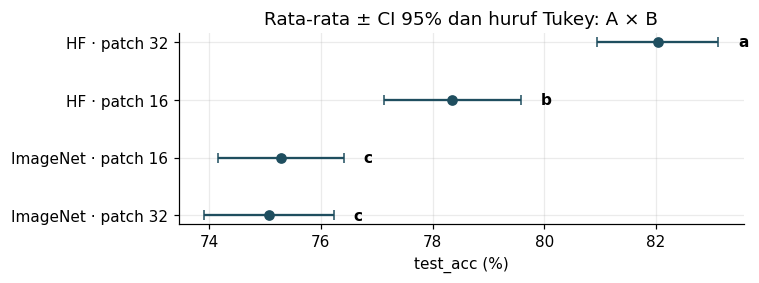


===== Tabel 7a. Kelompok C: rata-rata dan huruf Tukey (huruf sama = tidak berbeda nyata) =====


,Kelompok,n run,Rata-rata (%),SD (%),Huruf
0,n = 16,40,80.2,3.6,a
1,n = 14,40,79.5,4.4,a
2,n = 10,40,76.2,3.8,b
3,n = 8,40,74.9,4.2,b


Tabel 7b. Perbandingan berpasangan (Tukey HSD, galat model ber-blok, db galat = 135)



,Pembanding,Selisih (poin %),p-adj,Sig.,CI95 bawah,CI95 atas
0,n = 8 vs n = 10,-1.3,0.1537,ns,-2.8,+0.3
1,n = 8 vs n = 14,-4.6,<0.001,***,-6.1,-3.0
2,n = 8 vs n = 16,-5.3,<0.001,***,-6.8,-3.7
3,n = 10 vs n = 14,-3.3,<0.001,***,-4.9,-1.8
4,n = 10 vs n = 16,-4.0,<0.001,***,-5.6,-2.5
5,n = 14 vs n = 16,-0.7,0.6131,ns,-2.3,+0.8


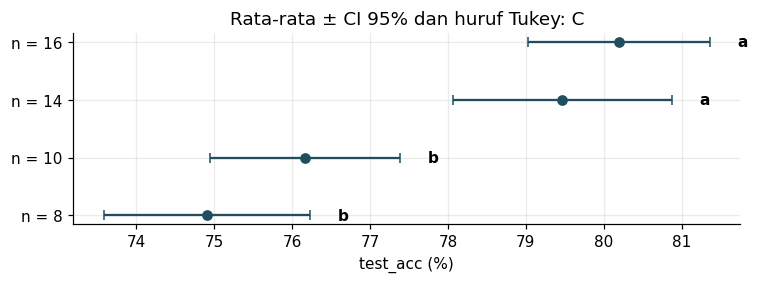

In [6]:
# Uji lanjut Tukey HSD dengan galat (MSE) dari model ber-blok, sehingga efek blok ikut dikeluarkan.
# Faktor yang tidak dibandingkan dirata-ratakan; itu sah bila interaksinya dengan faktor tsb tidak nyata (dicek otomatis).
POSTHOC = [["source", "patch"], ["train_n"]]      # tambah ["source","patch","train_n"] untuk 16 sel
TERMF = {"A×B": {"source", "patch"}, "A×C": {"source", "train_n"}, "B×C": {"patch", "train_n"},
         "A×B×C": {"source", "patch", "train_n"}}
mse, dfe = model.mse_resid, model.df_resid

def level_name(col, v):
    return f"patch {v}" if col == "patch" else f"n = {v}" if col == "train_n" else str(v)

def cld(means, nonsig):
    """Huruf kelompok (Tukey, desain seimbang): kelompok berhuruf sama = tidak berbeda nyata."""
    order = np.argsort(-np.asarray(means), kind="stable"); m = len(order)
    ranges = []
    for a in range(m):
        b = a
        while b + 1 < m and nonsig[order[a]][order[b + 1]]:
            b += 1
        ranges.append((a, b))
    keep = sorted({r for r in ranges if not any(o != r and o[0] <= r[0] and o[1] >= r[1] for o in ranges)})
    letters = {i: "" for i in range(m)}
    for li, (a, b) in enumerate(keep):
        for pos in range(a, b + 1):
            letters[order[pos]] += chr(97 + li)
    return letters

def tukey_blocked(cols):
    gb = df.groupby(cols, observed=True)
    g = pd.DataFrame({"ym": gb["y"].mean(), "n": gb["y"].count(), "mean": gb[RESP].mean(), "sd": gb[RESP].std()})
    names = [" · ".join(level_name(c, v) for c, v in zip(cols, (i if isinstance(i, tuple) else (i,)))) for i in g.index]
    k = len(g); crit = studentized_range.ppf(1 - ALPHA, k, dfe)
    nonsig = np.ones((k, k), dtype=bool); rows = []
    for i, j in combinations(range(k), 2):
        d = g["ym"].iloc[i] - g["ym"].iloc[j]
        se = np.sqrt(mse / 2 * (1 / g["n"].iloc[i] + 1 / g["n"].iloc[j]))
        p = float(studentized_range.sf(abs(d) / se, k, dfe))
        nonsig[i][j] = nonsig[j][i] = p >= ALPHA
        r = {"Pembanding": f"{names[i]}  vs  {names[j]}",
             "Selisih (poin %)": 100 * (g["mean"].iloc[i] - g["mean"].iloc[j]), "p-adj": p, "Sig.": star(p)}
        if not ASIN_SQRT:
            r["CI95 bawah"] = 100 * (d - crit * se); r["CI95 atas"] = 100 * (d + crit * se)
        rows.append(r)
    letters = cld(g["ym"].values, nonsig)
    grp = pd.DataFrame({"Kelompok": names, "n run": g["n"].values, "Rata-rata (%)": 100 * g["mean"].values,
                        "SD (%)": 100 * g["sd"].values, "Huruf": [letters[i] for i in range(k)]})
    grp = grp.sort_values("Rata-rata (%)", ascending=False).reset_index(drop=True)
    return pd.DataFrame(rows), grp

for n_tab, cols in enumerate(POSTHOC, start=6):
    E = [f for f in FACTORS if f not in cols]
    bad = [t for t, fs in TERMF.items() if t in tab.index and tab.loc[t, "p"] < ALPHA and fs & set(cols) and fs & set(E)]
    title = " × ".join(FNAME[c].split(":")[0] for c in cols)
    print(f"\n===== Tabel {n_tab}a. Kelompok {title}: rata-rata dan huruf Tukey (huruf sama = tidak berbeda nyata) =====")
    if bad:
        print(f"PERHATIAN: interaksi {bad} nyata, rata-rata marginal ini bisa menyesatkan; baca per sel.")
    pairs, grp = tukey_blocked(cols)
    display(grp.style.format({"Rata-rata (%)": "{:.1f}", "SD (%)": "{:.1f}"}))
    print(f"Tabel {n_tab}b. Perbandingan berpasangan (Tukey HSD, galat model ber-blok, db galat = {int(dfe)})\n")
    fmt = {"Selisih (poin %)": "{:+.1f}", "p-adj": fp, "CI95 bawah": "{:+.1f}", "CI95 atas": "{:+.1f}"}
    display(pairs.style.format({k: v for k, v in fmt.items() if k in pairs.columns})
            .apply(lambda r: ["font-weight:bold" if r["p-adj"] < ALPHA else "" for _ in r], axis=1))
    key = "_".join(cols)
    grp.to_csv(f"{OUT}/tabel{n_tab}a_{key}_huruf.csv", index=False); pairs.to_csv(f"{OUT}/tabel{n_tab}b_{key}_pasangan.csv", index=False)

    # gambar: titik + CI95 + huruf
    gg = grp.iloc[::-1].reset_index(drop=True)
    ci = stats.t.ppf(.975, gg["n run"] - 1) * gg["SD (%)"] / np.sqrt(gg["n run"])
    fig, ax = plt.subplots(figsize=(7, max(2.4, .42 * len(gg) + 1)))
    ax.errorbar(gg["Rata-rata (%)"], range(len(gg)), xerr=ci, fmt="o", color="#1F4E5F", capsize=3)
    for i, r in gg.iterrows():
        ax.text(r["Rata-rata (%)"] + ci[i] + .35, i, r["Huruf"], va="center", fontweight="bold")
    ax.set_yticks(range(len(gg)), gg["Kelompok"]); ax.set_xlabel(f"{RESP} (%)")
    ax.set_title(f"Rata-rata ± CI 95% dan huruf Tukey: {title}")
    save(fig, f"gambar{n_tab}_posthoc_{key}")

## 6. Ekspor

In [7]:
files = sorted(os.listdir(OUT))
print(f"{len(files)} file tersimpan di {OUT}:")
for f in files:
    print("  ", f)

16 file tersimpan di anova_test_acc:
   gambar0_residual.png
   gambar1_interaksi.png
   gambar2_boxplot.png
   gambar3_efek_utama.png
   gambar4_heatmap.png
   gambar5_blok.png
   gambar6_posthoc_source_patch.png
   gambar7_posthoc_train_n.png
   tabel1_mean_sd.csv
   tabel3_marginal.csv
   tabel4_anova.csv
   tabel5_asumsi.csv
   tabel6a_source_patch_huruf.csv
   tabel6b_source_patch_pasangan.csv
   tabel7a_train_n_huruf.csv
   tabel7b_train_n_pasangan.csv


## Catatan untuk penulisan hasil
- **Resolusi tercampur pada patch 32.** HuggingFace patch 32 memakai 384 px, ImageNet 224 px. Interaksi sumber×patch tidak dapat dibaca sebagai efek patch murni.
- **Nilai-p cenderung optimis.** Semua blok mengacak ulang 120 sampel yang sama, jadi test set antar blok saling tumpang tindih. Kesimpulan paling kuat berlaku untuk kumpulan sampel ini; `pred_acc` (sampel eksternal) dipakai sebagai pengecekan.
- **Backbone beku:** kesimpulan berlaku untuk pelatihan head di atas fitur beku, bukan fine-tuning penuh.
- Bila `loss_drop_last10` pada notebook model belum mendekati nol, lakukan uji sensitivitas dengan epoch lebih besar sebelum menyimpulkan efek sumber.